# DFUTissue: WoundFormer vs DFUTissueSegNet vs WoundFormer-GL — multiple seeds

Same protocol as the single-seed notebook, repeated over the seeds you choose. Reports mean ± SD over seeds, the best single run, the seed-paired difference of every model against WoundFormer, and compares with the paper's Table 3. Finished runs are skipped, so you can stop and resume, or add seeds later.

| setting | meaning |
|---|---|
| `DATA_ROOT` | the DFUTissue folder that contains `Labeled/` (from github.com/uwm-bigdata/DFUTissueSegNet, folder `DFUTissue`) |
| `MODELS` | any of `woundformer`, `dfutissuesegnet`, `woundformer_gl` |
| `SETTINGS` | `noaug` = without augmentation, `aug` = DFUTissueSegNet augmentation |
| `EPOCHS` | 200 = the paper's protocol (early stopping ends runs much earlier); 1–2 = quick check that everything runs |
| `RETRAIN` | `False`: finished runs (with `results.json`) are skipped, so the notebook can be re-run / resumed |
| `KEEP_WEIGHTS` | keep `best.pth` (~330 MB for WoundFormer / -GL, ~190 MB for DFUTissueSegNet) |

Approximate time per run on an 8 GB RTX 4060: WoundFormer 2–3 min, DFUTissueSegNet 2–4 min, WoundFormer-GL 15–25 min
(it processes the full image plus four tiles; activation checkpointing is switched on automatically to fit 8 GB).

In [1]:
# ---- settings ----------------------------------------------------------------------------------
import os
DATA_ROOT = os.environ.get("WOUNDSEG_DATA", r"/home/yash/Desktop/Aizhan/WoundSegmentation/DFUTissue")   # folder that contains Labeled/
SEEDS = [int(s) for s in os.environ.get("WOUNDSEG_SEEDS", "0 1 2 3 4").split()]   # choose your seeds
MODELS = ["woundformer", "dfutissuesegnet", "woundformer_gl"]
SETTINGS = os.environ.get("WOUNDSEG_SETTINGS", "noaug aug").split()   # "noaug" and/or "aug"
EPOCHS = int(os.environ.get("WOUNDSEG_EPOCHS", 200))
RUNS_ROOT = os.environ.get("WOUNDSEG_RUNS", "runs")
RETRAIN = False
KEEP_WEIGHTS = False   # 3 models x 2 settings x 5 seeds of weights would be ~25 GB
SHOW_SEED = SEEDS[0]   # seed used for the qualitative figure

## Environment and data check

In [2]:
import os, sys, subprocess, time
from pathlib import Path

# repository root (this notebook lives in <repo>/notebooks)
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(REPO)
sys.path.insert(0, str(REPO))

import torch
from IPython.display import Markdown, display
print("repo   :", REPO)
print("torch  :", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print("GPU    :", p.name, f"{p.total_memory / 2**30:.1f} GB")

# dataset check
lab = Path(DATA_ROOT) / "Labeled"
for f in ["labeled_train_names.txt", "labeled_val_names.txt", "test_names.txt"]:
    assert (lab / f).exists(), f"missing {lab / f}: set DATA_ROOT to the DFUTissue folder that contains Labeled/"
for sub in ["Images/TrainVal", "Images/Test", "Annotations/TrainVal", "Annotations/Test"]:
    n = len(list((lab / "Original" / sub).glob("*.png")))
    print(f"Original/{sub:22s} {n} files")


repo   : /home/yash/Downloads/WoundTissueSeg_code/WoundTissueSeg
torch  : 2.14.1+cu130 | CUDA available: True
GPU    : NVIDIA GeForce RTX 4090 23.5 GB
Original/Images/TrainVal        93 files
Original/Images/Test            16 files
Original/Annotations/TrainVal   93 files
Original/Annotations/Test       16 files


## Train, validate and test (seed by seed, so early seeds give complete comparisons first)

In [3]:
def run_dir(model, setting, seed):
    return Path(RUNS_ROOT) / f"{model}_{setting}_s{seed}"


def train(model, setting, seed):
    """Runs train.py in a separate process (clean GPU memory per run) and streams its output."""
    out = run_dir(model, setting, seed)
    if (out / "results.json").exists() and not RETRAIN:
        print(f"[skip] {out} already finished (set RETRAIN = True to train again)")
        return
    cmd = [sys.executable, "-W", "ignore", "train.py", "--model", model, "--data-root", str(DATA_ROOT),
           "--seed", str(seed), "--epochs", str(EPOCHS), "--runs-root", str(RUNS_ROOT)]
    if setting == "aug":
        cmd.append("--aug")
    if not KEEP_WEIGHTS:
        cmd.append("--no-ckpt")
    print(f"\n=== {model} | {setting} | seed {seed} ===", flush=True)
    t0 = time.time()
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in proc.stdout:
        print(line, end="", flush=True)
    if proc.wait() != 0:
        raise RuntimeError(f"training failed: {' '.join(cmd)}")
    print(f"[done] {out}  ({(time.time() - t0) / 60:.1f} min)")


In [4]:
for seed in SEEDS:
    for setting in SETTINGS:
        for model in MODELS:
            train(model, setting, seed)

[skip] runs/woundformer_noaug_s0 already finished (set RETRAIN = True to train again)
[skip] runs/dfutissuesegnet_noaug_s0 already finished (set RETRAIN = True to train again)
[skip] runs/woundformer_gl_noaug_s0 already finished (set RETRAIN = True to train again)
[skip] runs/woundformer_aug_s0 already finished (set RETRAIN = True to train again)
[skip] runs/dfutissuesegnet_aug_s0 already finished (set RETRAIN = True to train again)
[skip] runs/woundformer_gl_aug_s0 already finished (set RETRAIN = True to train again)

=== woundformer | noaug | seed 1 ===
[data] train 78  val 15  test 16  (Original)
[model] woundformer: 81.82M parameters (decoder/heads 0.38M)  device cuda
ep   1 lr 1e-04 train 1.0551 val 1.0955 mIoU 20.48 valDice 22.52 * (1.8s)
ep   2 lr 1e-04 train 0.5417 val 0.6223 mIoU 20.48 valDice 22.52  (1.2s)
ep   3 lr 1e-04 train 0.4263 val 0.4425 mIoU 25.27 valDice 30.75 * (2.8s)
ep   4 lr 1e-04 train 0.3432 val 0.4070 mIoU 39.88 valDice 50.00 * (2.7s)
ep   5 lr 1e-04 train 0.

## Results vs the paper: mean ± SD over seeds, best run, paired differences

In [5]:
from compare_with_paper import compare
report = compare(RUNS_ROOT, MODELS, SETTINGS, SEEDS)
Path('figures').mkdir(exist_ok=True)
Path('figures/comparison.md').write_text(report, encoding='utf-8')
display(Markdown(report))

Test Dice (%), dataset-level, test_224. Paper rows = single runs of Table 3; best run = seed with the highest Avg (4); mean ± SD over the seeds found.

### DFUTissue, without augmentation

| Model | runs | Gran | Fibrin | Callus | Back | Avg (4) | Tissue (3) | FG |
|---|---|---|---|---|---|---|---|---|
| WoundFormer (paper) | 1 | 82.45 | 69.32 | 86.71 | 74.88 | 78.34 | 79.49 | – |
| DFUTissueSegNet (paper) | 1 | 90.75 | 68.40 | 82.31 | 76.50 | 79.49 | 80.49 | – |
| WoundFormer (ours), best run (seed 0) | 1 | 91.33 | 81.10 | 72.42 | 94.07 | 84.73 | 81.62 | 86.29 |
| WoundFormer (ours), seeds 0,1,2,3,4 | 5 | 89.93 ± 1.62 | 65.45 ± 9.62 | 73.39 ± 1.34 | 93.76 ± 0.21 | 80.63 ± 2.53 | 76.26 ± 3.33 | 85.63 ± 0.39 |
| DFUTissueSegNet (ours), best run (seed 1) | 1 | 90.89 | 74.46 | 74.17 | 94.48 | 83.50 | 79.84 | 87.44 |
| DFUTissueSegNet (ours), seeds 0,1,2,3,4 | 5 | 88.67 ± 1.74 | 65.53 ± 5.13 | 73.56 ± 2.22 | 93.93 ± 0.49 | 80.42 ± 1.77 | 75.92 ± 2.25 | 86.27 ± 1.16 |
| WoundFormer-GL (ours), best run (seed 3) | 1 | 92.31 | 78.98 | 75.78 | 94.44 | 85.38 | 82.36 | 86.92 |
| WoundFormer-GL (ours), seeds 0,1,2,3,4 | 5 | 92.29 ± 0.46 | 74.76 ± 6.68 | 76.65 ± 1.65 | 94.58 ± 0.28 | 84.57 ± 1.29 | 81.23 ± 1.79 | 87.76 ± 0.96 |

Seed-paired difference vs your WoundFormer (without augmentation): mean Δ (seeds improved)

| Model | shared seeds | Gran | Fibrin | Callus | Back | Avg (4) | Tissue (3) | FG |
|---|---|---|---|---|---|---|---|---|
| DFUTissueSegNet | 0,1,2,3,4 | -1.26 (1/5) | +0.08 (3/5) | +0.17 (3/5) | +0.17 (3/5) | -0.21 (3/5) | -0.34 (3/5) | +0.64 (3/5) |
| WoundFormer-GL | 0,1,2,3,4 | +2.36 (5/5) | +9.31 (4/5) | +3.26 (5/5) | +0.82 (5/5) | +3.94 (4/5) | +4.98 (4/5) | +2.13 (5/5) |

WoundFormer: your mean minus the paper's run: Gran +7.48, Fibrin -3.87, Callus -13.32, Back +18.88, Avg (4) +2.29, Tissue (3) -3.23

DFUTissueSegNet: your mean minus the paper's run: Gran -2.08, Fibrin -2.87, Callus -8.75, Back +17.43, Avg (4) +0.93, Tissue (3) -4.57

### DFUTissue, with augmentation

| Model | runs | Gran | Fibrin | Callus | Back | Avg (4) | Tissue (3) | FG |
|---|---|---|---|---|---|---|---|---|
| WoundFormer (paper) | 1 | 88.27 | 70.75 | 87.42 | 95.13 | 85.40 | 82.15 | – |
| DFUTissueSegNet (paper) | 1 | 91.99 | 74.52 | 85.91 | 95.90 | 87.08 | 84.14 | – |
| WoundFormer (ours), best run (seed 0) | 1 | 92.81 | 84.88 | 75.70 | 94.49 | 86.97 | 84.46 | 87.77 |
| WoundFormer (ours), seeds 0,1,2,3,4 | 5 | 91.43 ± 0.86 | 77.85 ± 4.52 | 75.46 ± 1.22 | 94.16 ± 0.61 | 84.72 ± 1.53 | 81.58 ± 1.90 | 87.24 ± 1.13 |
| DFUTissueSegNet (ours), best run (seed 2) | 1 | 92.47 | 82.36 | 77.48 | 94.91 | 86.80 | 84.10 | 88.80 |
| DFUTissueSegNet (ours), seeds 0,1,2,3,4 | 5 | 91.09 ± 1.01 | 76.76 ± 3.38 | 76.03 ± 1.57 | 94.43 ± 0.34 | 84.58 ± 1.34 | 81.29 ± 1.68 | 87.57 ± 0.94 |
| WoundFormer-GL (ours), best run (seed 3) | 1 | 93.19 | 83.89 | 77.29 | 94.32 | 87.17 | 84.79 | 87.78 |
| WoundFormer-GL (ours), seeds 0,1,2,3,4 | 5 | 92.25 ± 1.09 | 81.71 ± 2.37 | 77.31 ± 1.51 | 94.49 ± 0.46 | 86.44 ± 0.79 | 83.76 ± 1.01 | 87.83 ± 0.98 |

Seed-paired difference vs your WoundFormer (with augmentation): mean Δ (seeds improved)

| Model | shared seeds | Gran | Fibrin | Callus | Back | Avg (4) | Tissue (3) | FG |
|---|---|---|---|---|---|---|---|---|
| DFUTissueSegNet | 0,1,2,3,4 | -0.34 (2/5) | -1.09 (3/5) | +0.57 (2/5) | +0.27 (3/5) | -0.15 (2/5) | -0.29 (2/5) | +0.33 (3/5) |
| WoundFormer-GL | 0,1,2,3,4 | +0.82 (5/5) | +3.86 (4/5) | +1.85 (5/5) | +0.33 (4/5) | +1.72 (4/5) | +2.18 (4/5) | +0.59 (4/5) |

WoundFormer: your mean minus the paper's run: Gran +3.16, Fibrin +7.10, Callus -11.96, Back -0.97, Avg (4) -0.68, Tissue (3) -0.57

DFUTissueSegNet: your mean minus the paper's run: Gran -0.90, Fibrin +2.24, Callus -9.88, Back -1.47, Avg (4) -2.50, Tissue (3) -2.85


## Per-seed results

In [6]:
from compare_with_paper import per_seed_markdown
display(Markdown(per_seed_markdown(RUNS_ROOT, MODELS, SETTINGS, SEEDS)))

| setting | model | seed | Gran | Fibrin | Callus | Back | Avg (4) | Tissue (3) | FG |
|---|---|---|---|---|---|---|---|---|---|
| noaug | WoundFormer | 0 | 91.33 | 81.10 | 72.42 | 94.07 | 84.73 | 81.62 | 86.29 |
| noaug | WoundFormer | 1 | 91.61 | 66.21 | 72.26 | 93.72 | 80.95 | 76.69 | 85.56 |
| noaug | WoundFormer | 2 | 90.20 | 63.03 | 72.61 | 93.57 | 79.85 | 75.28 | 85.43 |
| noaug | WoundFormer | 3 | 88.36 | 61.70 | 75.11 | 93.60 | 79.69 | 75.06 | 85.29 |
| noaug | WoundFormer | 4 | 88.15 | 55.23 | 74.56 | 93.85 | 77.95 | 72.65 | 85.55 |
| noaug | DFUTissueSegNet | 0 | 86.26 | 63.85 | 74.99 | 93.78 | 79.72 | 75.03 | 86.15 |
| noaug | DFUTissueSegNet | 1 | 90.89 | 74.46 | 74.17 | 94.48 | 83.50 | 79.84 | 87.44 |
| noaug | DFUTissueSegNet | 2 | 89.64 | 61.29 | 75.76 | 94.37 | 80.26 | 75.56 | 87.37 |
| noaug | DFUTissueSegNet | 3 | 88.07 | 64.24 | 70.13 | 93.70 | 79.04 | 74.15 | 84.75 |
| noaug | DFUTissueSegNet | 4 | 88.49 | 63.82 | 72.75 | 93.32 | 79.60 | 75.02 | 85.62 |
| noaug | WoundFormer-GL | 0 | 92.84 | 64.25 | 77.67 | 94.80 | 82.39 | 78.25 | 88.64 |
| noaug | WoundFormer-GL | 1 | 92.64 | 76.56 | 77.56 | 94.69 | 85.36 | 82.25 | 88.39 |
| noaug | WoundFormer-GL | 2 | 91.83 | 81.30 | 74.16 | 94.17 | 85.37 | 82.43 | 86.53 |
| noaug | WoundFormer-GL | 3 | 92.31 | 78.98 | 75.78 | 94.44 | 85.38 | 82.36 | 86.92 |
| noaug | WoundFormer-GL | 4 | 91.82 | 72.72 | 78.09 | 94.80 | 84.36 | 80.88 | 88.32 |
| aug | WoundFormer | 0 | 92.81 | 84.88 | 75.70 | 94.49 | 86.97 | 84.46 | 87.77 |
| aug | WoundFormer | 1 | 91.66 | 76.59 | 75.90 | 94.70 | 84.71 | 81.38 | 88.32 |
| aug | WoundFormer | 2 | 90.97 | 78.54 | 74.22 | 93.84 | 84.39 | 81.24 | 86.19 |
| aug | WoundFormer | 3 | 90.64 | 72.46 | 74.33 | 93.24 | 82.66 | 79.14 | 85.86 |
| aug | WoundFormer | 4 | 91.05 | 76.80 | 77.16 | 94.53 | 84.89 | 81.67 | 88.05 |
| aug | DFUTissueSegNet | 0 | 91.19 | 74.63 | 76.94 | 94.45 | 84.30 | 80.92 | 87.88 |
| aug | DFUTissueSegNet | 1 | 89.97 | 73.71 | 75.53 | 94.05 | 83.31 | 79.74 | 86.34 |
| aug | DFUTissueSegNet | 2 | 92.47 | 82.36 | 77.48 | 94.91 | 86.80 | 84.10 | 88.80 |
| aug | DFUTissueSegNet | 3 | 91.56 | 76.05 | 73.52 | 94.18 | 83.83 | 80.38 | 87.00 |
| aug | DFUTissueSegNet | 4 | 90.23 | 77.07 | 76.66 | 94.58 | 84.63 | 81.32 | 87.81 |
| aug | WoundFormer-GL | 0 | 93.37 | 83.67 | 75.89 | 94.36 | 86.82 | 84.31 | 87.75 |
| aug | WoundFormer-GL | 1 | 92.43 | 81.99 | 78.61 | 95.01 | 87.01 | 84.34 | 88.83 |
| aug | WoundFormer-GL | 2 | 91.13 | 80.92 | 75.74 | 93.87 | 85.42 | 82.60 | 86.29 |
| aug | WoundFormer-GL | 3 | 93.19 | 83.89 | 77.29 | 94.32 | 87.17 | 84.79 | 87.78 |
| aug | WoundFormer-GL | 4 | 91.11 | 78.09 | 79.04 | 94.87 | 85.78 | 82.75 | 88.50 |


## Per-class comparison with the paper (mean ± SD over seeds)

saved figures/bars_noaug.png


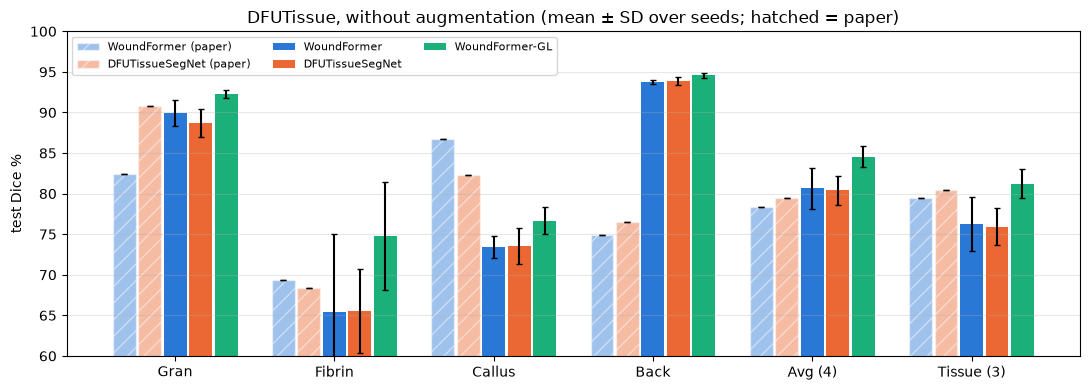

saved figures/bars_aug.png


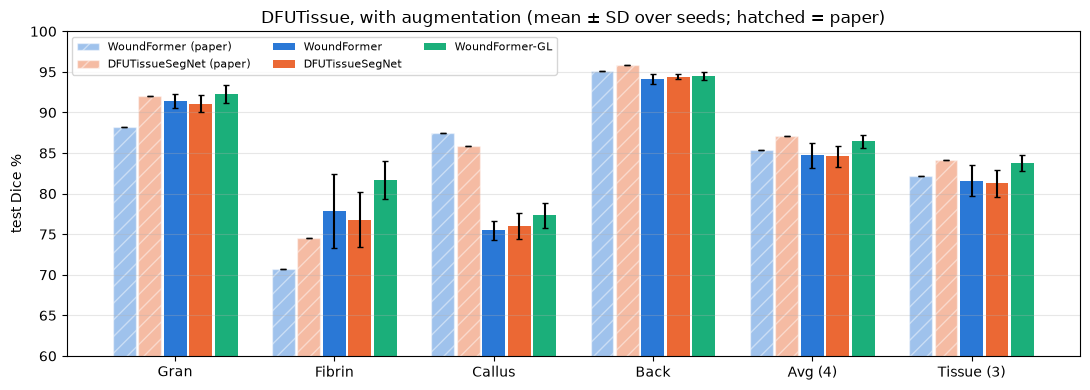

In [7]:
%matplotlib inline
import matplotlib.pyplot as plt
import visualize
for setting in SETTINGS:
    fig = visualize.bars(RUNS_ROOT, setting, SEEDS, MODELS, out=f'figures/bars_{setting}.png')
    plt.show()

## Training curves and qualitative results for `SHOW_SEED`

saved figures/curves_noaug_s0.png


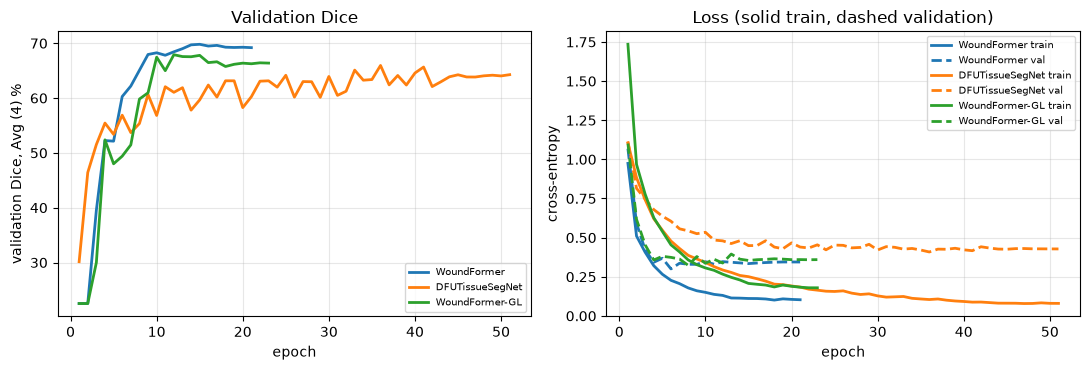

saved figures/qualitative_noaug_s0.png


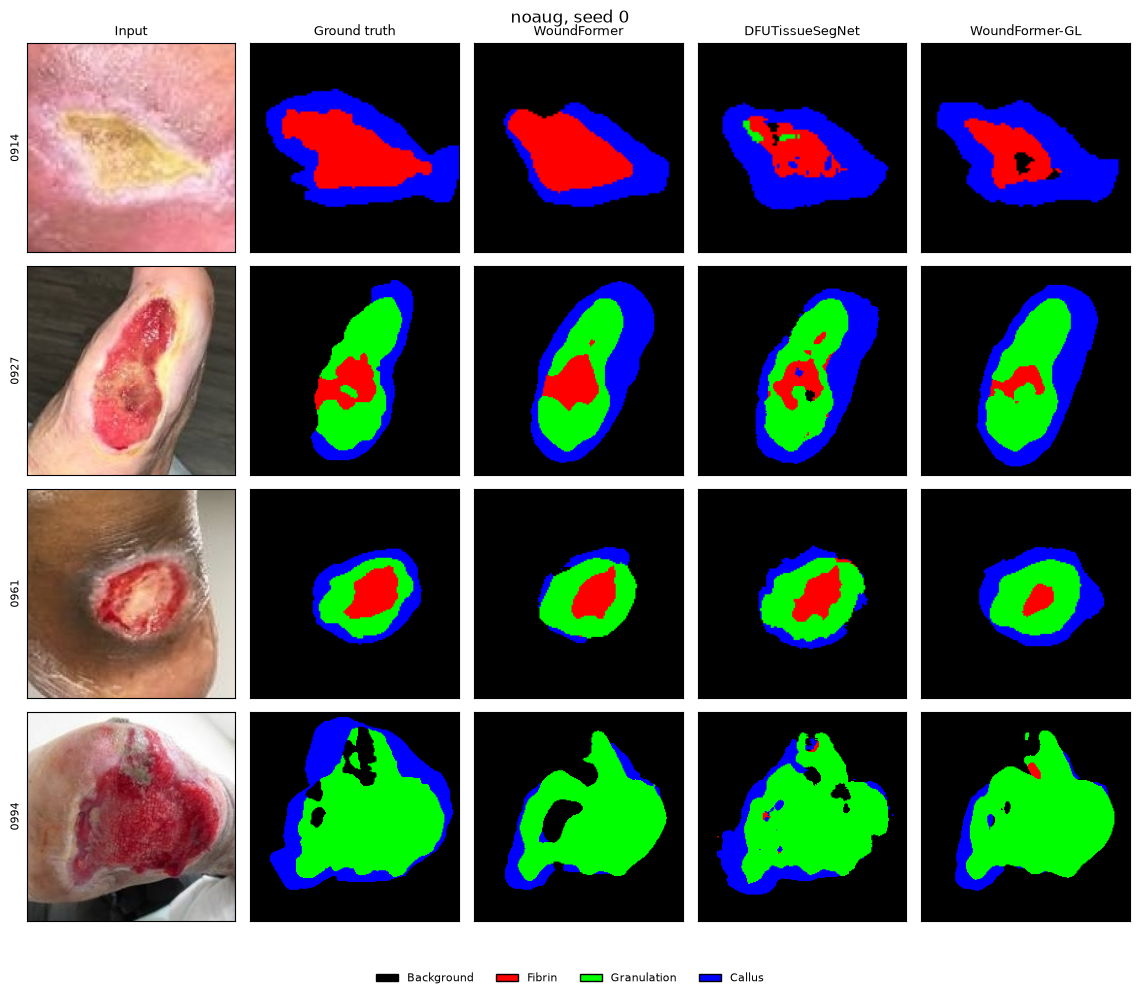

saved figures/curves_aug_s0.png


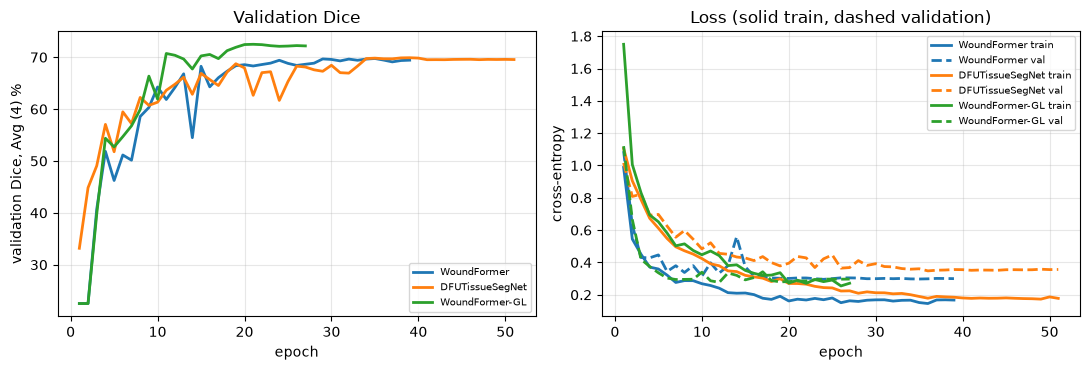

saved figures/qualitative_aug_s0.png


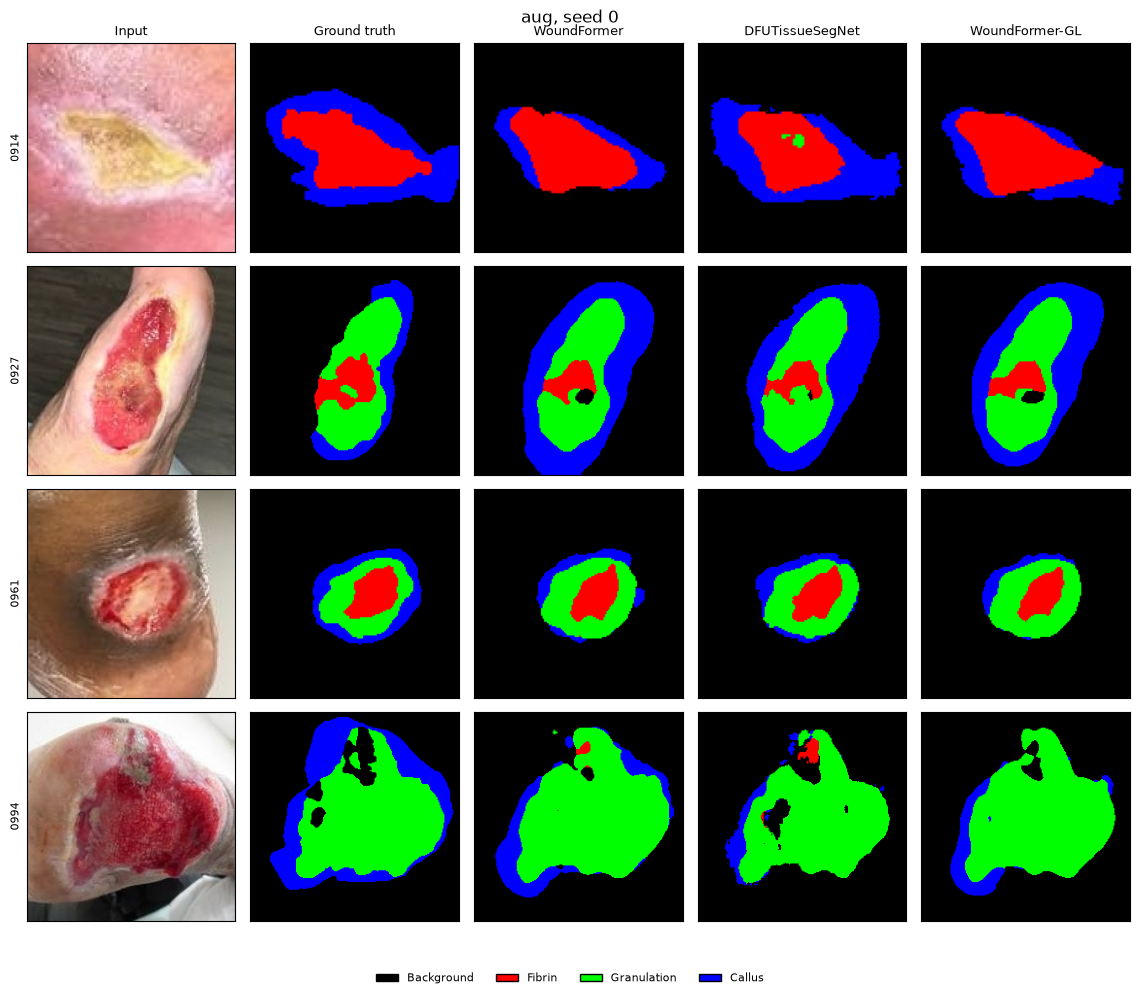

In [8]:
IMAGES = ['0914', '0927', '0961', '0994']
labels = {'woundformer': 'WoundFormer', 'dfutissuesegnet': 'DFUTissueSegNet', 'woundformer_gl': 'WoundFormer-GL'}
for setting in SETTINGS:
    ms = [m for m in MODELS if (run_dir(m, setting, SHOW_SEED) / 'test_pred').exists()]
    if not ms:
        continue
    runs = [str(run_dir(m, setting, SHOW_SEED)) for m in ms]
    visualize.curves(runs, [labels[m] for m in ms], out=f'figures/curves_{setting}_s{SHOW_SEED}.png'); plt.show()
    fig = visualize.qualitative(runs, [labels[m] for m in ms], DATA_ROOT, IMAGES,
                                out=f'figures/qualitative_{setting}_s{SHOW_SEED}.png')
    fig.suptitle(f'{setting}, seed {SHOW_SEED}', y=1.0); plt.show()